In [1]:
import time
import random
import sys


# -------------------------------------------------
# Fractional Knapsack using Greedy Strategy
# -------------------------------------------------
def fractional_knapsack(items, capacity):

    items_with_ratio = []

    # Calculate value/weight ratio
    for item_id, value, weight in items:
        ratio = value / weight

        items_with_ratio.append(
            [item_id, value, weight, ratio, 0.0]
        )

    # Sort by ratio in descending order
    items_with_ratio.sort(
        key=lambda x: x[3],
        reverse=True
    )

    remaining_capacity = capacity
    total_value = 0.0

    # Select items greedily
    for item in items_with_ratio:

        if remaining_capacity <= 0:
            break

        item_id, value, weight, ratio, fraction = item

        # Take complete item
        if weight <= remaining_capacity:

            item[4] = 1.0
            remaining_capacity -= weight
            total_value += value

        # Take fraction of item
        else:

            fraction = remaining_capacity / weight

            item[4] = fraction

            total_value += value * fraction

            remaining_capacity = 0

    return items_with_ratio, total_value





In [2]:
import time
import sys


def run_knapsack(items, capacity):

    # Start time
    start = time.perf_counter()

    selected_items, total_value = fractional_knapsack(
        items,
        capacity
    )

    # End time
    end = time.perf_counter()

    # Time taken in microseconds
    time_taken = (end - start) * 1_000_000

    # Calculate space used
    space = sys.getsizeof(items)

    for item in items:
        space += sys.getsizeof(item)

    # Display results
    print("\nSelected Items:")

    for item in selected_items:
        print(item)

    print("\nMaximum Value:", total_value)
    print("Time Taken:", time_taken, "microseconds")
    print("Space Used:", space, "bytes")


# Input
items = [
    (1, 60, 10),
    (2, 100, 20),
    (3, 120, 30)
]

capacity = 50

# Function call
run_knapsack(items, capacity)


Selected Items:
[1, 60, 10, 6.0, 1.0]
[2, 100, 20, 5.0, 1.0]
[3, 120, 30, 4.0, 0.6666666666666666]

Maximum Value: 240.0
Time Taken: 21.799991372972727 microseconds
Space Used: 280 bytes


In [3]:
def knapsack_01(items, capacity):

    n = len(items)

    # Create DP table
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    # Fill the table
    for i in range(1, n + 1):

        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):

            # Item cannot fit
            if weight > w:
                dp[i][w] = dp[i - 1][w]

            # Choose maximum of taking or not taking item
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    # Find selected items
    selected_items = []

    w = capacity

    for i in range(n, 0, -1):

        if dp[i][w] != dp[i - 1][w]:

            item_id, value, weight = items[i - 1]

            selected_items.append(item_id)

            w -= weight

    selected_items.reverse()

    return selected_items, dp[n][capacity]


# Input
items = [
    (1, 60, 10),
    (2, 100, 20),
    (3, 120, 30)
]

capacity = 50

# Function call
selected_items, maximum_value = knapsack_01(
    items,
    capacity
)

# Output
print("Selected Items:", selected_items)
print("Maximum Value:", maximum_value)

Selected Items: [2, 3]
Maximum Value: 220



-----------------------------
0/1 Knapsack Result
-----------------------------
N = 3
Capacity = 50
Selected Items: [1, 2, 3]
Maximum Value: 240

Theoretical Complexity:
Time Complexity: O(n × W)
Space Complexity: O(n × W)

Measured Performance:
Execution time: 8.049997268244624e-05 seconds
DP table space: 1944 bytes

-----------------------------
0/1 Knapsack Result
-----------------------------
N = 4
Capacity = 50
Selected Items: [1, 2, 3, 4]
Maximum Value: 400

Theoretical Complexity:
Time Complexity: O(n × W)
Space Complexity: O(n × W)

Measured Performance:
Execution time: 7.910002022981644e-05 seconds
DP table space: 2440 bytes

-----------------------------
0/1 Knapsack Result
-----------------------------
N = 5
Capacity = 50
Selected Items: [1, 2, 3, 4]
Maximum Value: 400

Theoretical Complexity:
Time Complexity: O(n × W)
Space Complexity: O(n × W)

Measured Performance:
Execution time: 7.41000403650105e-05 seconds
DP table space: 2904 bytes

-----------------------------
0/1 

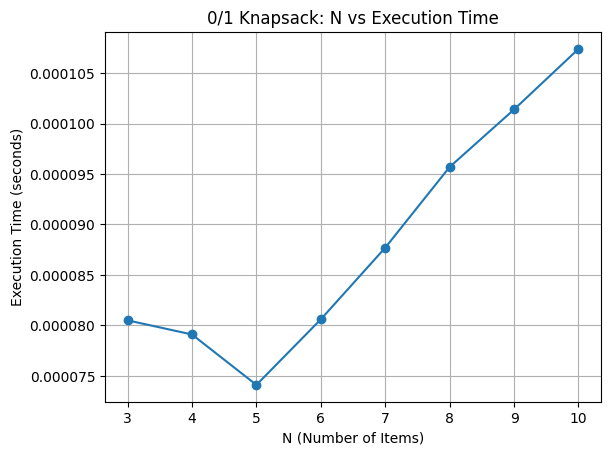

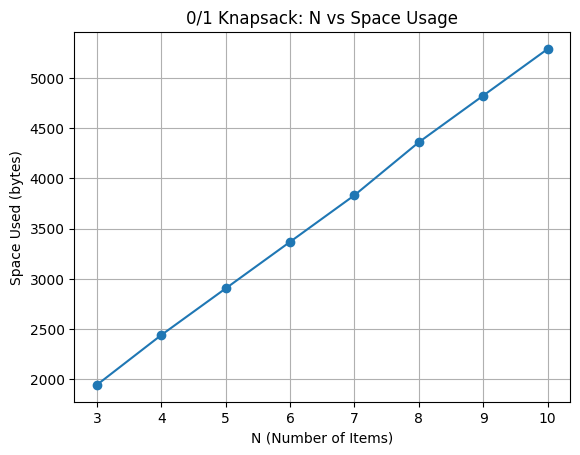

In [4]:

import time
import sys
import matplotlib.pyplot as plt


def knapsack_01(items, capacity):

    n = len(items)

    # Create DP table
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    # Fill the table
    for i in range(1, n + 1):

        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):

            # Item cannot fit
            if weight > w:
                dp[i][w] = dp[i - 1][w]

            # Choose maximum of taking or not taking item
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    # Find selected items
    selected_items = []

    w = capacity

    for i in range(n, 0, -1):

        if dp[i][w] != dp[i - 1][w]:

            item_id, value, weight = items[i - 1]

            selected_items.append(item_id)

            w -= weight

    selected_items.reverse()

    return selected_items, dp[n][capacity]


def run_knapsack(items, capacity):

    # Start measuring time
    start_time = time.perf_counter()

    selected_items, maximum_value = knapsack_01(
        items, capacity
    )

    # Stop measuring time
    end_time = time.perf_counter()

    execution_time = end_time - start_time

    # Measure DP table space
    dp = [[0] * (capacity + 1) for _ in range(len(items) + 1)]

    table_space = sys.getsizeof(dp) + sum(
        sys.getsizeof(row) for row in dp
    )

    print("\n-----------------------------")
    print("0/1 Knapsack Result")
    print("-----------------------------")

    print("N =", len(items))
    print("Capacity =", capacity)

    print("Selected Items:", selected_items)
    print("Maximum Value:", maximum_value)

    print("\nTheoretical Complexity:")
    print("Time Complexity: O(n × W)")
    print("Space Complexity: O(n × W)")

    print("\nMeasured Performance:")
    print("Execution time:", execution_time, "seconds")
    print("DP table space:", table_space, "bytes")

    return selected_items, maximum_value, execution_time, table_space


# -----------------------------------
# Test with multiple values of N
# -----------------------------------

n_values = []
execution_times = []
space_values = []

capacity = 50

for n in range(3, 11):

    # Generate n items
    items = []

    for i in range(1, n + 1):
        value = i * 40
        weight = i * 5

        items.append((i, value, weight))

    selected_items, maximum_value, execution_time, table_space = run_knapsack(
        items, capacity
    )

    n_values.append(n)
    execution_times.append(execution_time)
    space_values.append(table_space)


# -----------------------------------
# Plot Execution Time
# -----------------------------------

plt.figure()

plt.plot(
    n_values,
    execution_times,
    marker='o'
)

plt.xlabel("N (Number of Items)")
plt.ylabel("Execution Time (seconds)")
plt.title("0/1 Knapsack: N vs Execution Time")
plt.grid(True)

plt.show()


# -----------------------------------
# Plot Space Usage
# -----------------------------------

plt.figure()

plt.plot(
    n_values,
    space_values,
    marker='o'
)

plt.xlabel("N (Number of Items)")
plt.ylabel("Space Used (bytes)")
plt.title("0/1 Knapsack: N vs Space Usage")
plt.grid(True)

plt.show()



-----------------------------
Fractional Knapsack Result
-----------------------------
N = 3
Capacity = 50

Selected Items:
[1, 40, 5, 8.0, 1.0]
[2, 80, 10, 8.0, 1.0]
[3, 120, 15, 8.0, 1.0]

Maximum Value: 240.0

Theoretical Complexity:
Time Complexity: O(n log n)
Space Complexity: O(n)

Measured Performance:
Execution time: 1.1399970389902592e-05 seconds
Space used: 280 bytes

-----------------------------
Fractional Knapsack Result
-----------------------------
N = 4
Capacity = 50

Selected Items:
[1, 40, 5, 8.0, 1.0]
[2, 80, 10, 8.0, 1.0]
[3, 120, 15, 8.0, 1.0]
[4, 160, 20, 8.0, 1.0]

Maximum Value: 400.0

Theoretical Complexity:
Time Complexity: O(n log n)
Space Complexity: O(n)

Measured Performance:
Execution time: 9.599956683814526e-06 seconds
Space used: 344 bytes

-----------------------------
Fractional Knapsack Result
-----------------------------
N = 5
Capacity = 50

Selected Items:
[1, 40, 5, 8.0, 1.0]
[2, 80, 10, 8.0, 1.0]
[3, 120, 15, 8.0, 1.0]
[4, 160, 20, 8.0, 1.0]
[5

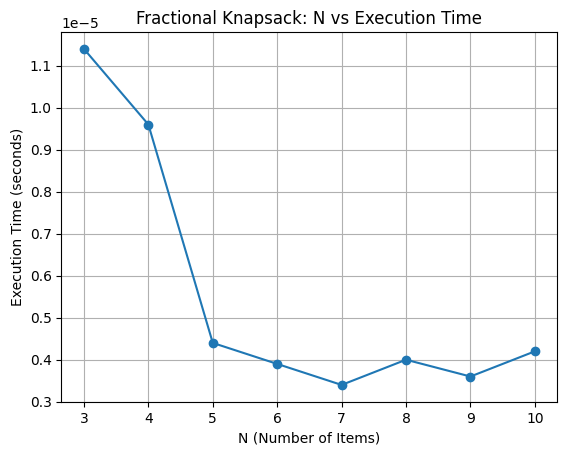

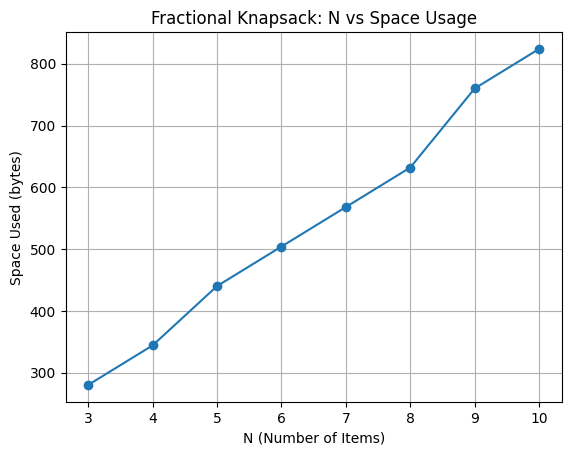

In [5]:

import time
import sys
import matplotlib.pyplot as plt


def run_knapsack(items, capacity):

    # Start measuring time
    start_time = time.perf_counter()

    selected_items, total_value = fractional_knapsack(
        items,
        capacity
    )

    # Stop measuring time
    end_time = time.perf_counter()

    execution_time = end_time - start_time

    # Calculate space used
    space = sys.getsizeof(items)

    for item in items:
        space += sys.getsizeof(item)

    # Display results
    print("\n-----------------------------")
    print("Fractional Knapsack Result")
    print("-----------------------------")

    print("N =", len(items))
    print("Capacity =", capacity)

    print("\nSelected Items:")

    for item in selected_items:
        print(item)

    print("\nMaximum Value:", total_value)

    print("\nTheoretical Complexity:")
    print("Time Complexity: O(n log n)")
    print("Space Complexity: O(n)")

    print("\nMeasured Performance:")
    print("Execution time:", execution_time, "seconds")
    print("Space used:", space, "bytes")

    return selected_items, total_value, execution_time, space


# -----------------------------------
# Test with multiple values of N
# -----------------------------------

n_values = []
execution_times = []
space_values = []

capacity = 50

for n in range(3, 11):

    # Generate n items
    items = []

    for i in range(1, n + 1):

        value = i * 40
        weight = i * 5

        items.append((i, value, weight))

    selected_items, total_value, execution_time, space = run_knapsack(
        items,
        capacity
    )

    # Store results
    n_values.append(n)
    execution_times.append(execution_time)
    space_values.append(space)


# -----------------------------------
# Plot Execution Time
# -----------------------------------

plt.figure()

plt.plot(
    n_values,
    execution_times,
    marker='o'
)

plt.xlabel("N (Number of Items)")
plt.ylabel("Execution Time (seconds)")
plt.title("Fractional Knapsack: N vs Execution Time")
plt.grid(True)

plt.show()


# -----------------------------------
# Plot Space Usage
# -----------------------------------

plt.figure()

plt.plot(
    n_values,
    space_values,
    marker='o'
)

plt.xlabel("N (Number of Items)")
plt.ylabel("Space Used (bytes)")
plt.title("Fractional Knapsack: N vs Space Usage")
plt.grid(True)

plt.show()


NameError: name 'fractional_times' is not defined

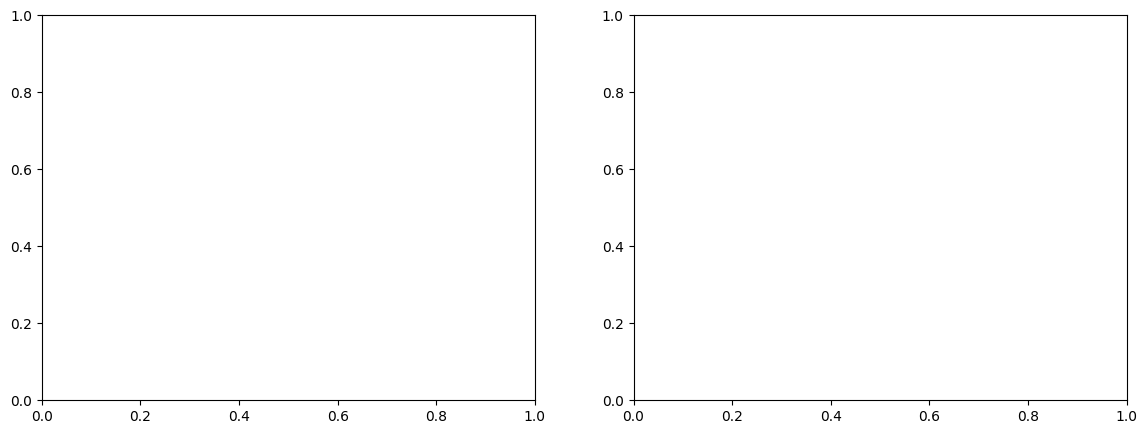

In [6]:
# ============================================================
# COMBINED GRAPHS: GREEDY vs DYNAMIC PROGRAMMING
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ------------------------------------------------------------
# Graph 1: Execution Time
# ------------------------------------------------------------

axes[0].plot(
    n_values,
    fractional_times,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[0].plot(
    n_values,
    zero_one_times,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[0].set_xlabel("N (Number of Items)")
axes[0].set_ylabel("Execution Time (seconds)")
axes[0].set_title("Execution Time: Greedy vs Dynamic Programming")
axes[0].legend()
axes[0].grid(True)


# ------------------------------------------------------------
# Graph 2: Space Usage
# ------------------------------------------------------------

axes[1].plot(
    n_values,
    fractional_spaces,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[1].plot(
    n_values,
    zero_one_spaces,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[1].set_xlabel("N (Number of Items)")
axes[1].set_ylabel("Measured Space (bytes)")
axes[1].set_title("Space Usage: Greedy vs Dynamic Programming")
axes[1].legend()
axes[1].grid(True)


# ------------------------------------------------------------
# Display both graphs in one figure
# ------------------------------------------------------------

fig.suptitle(
    "Performance Comparison: Greedy vs Dynamic Programming",
    fontsize=14
)

plt.tight_layout()
plt.show()

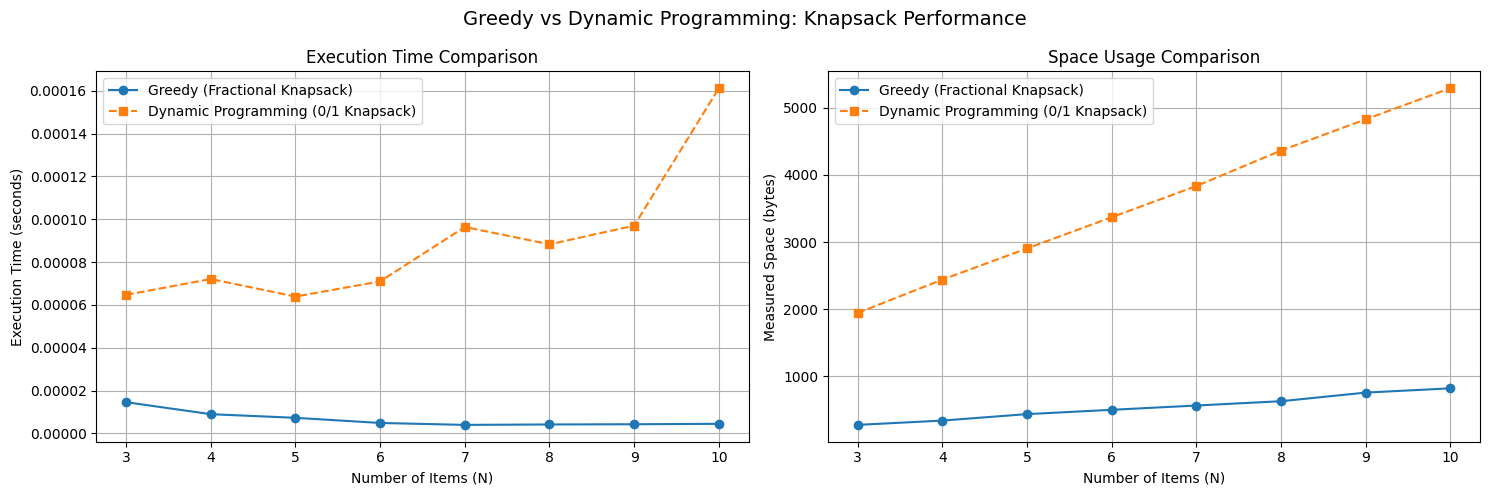

In [7]:
import time
import sys
import matplotlib.pyplot as plt


# ============================================================
# 1. GREEDY ALGORITHM - FRACTIONAL KNAPSACK
# ============================================================

def fractional_knapsack(items, capacity):
    sorted_items = sorted(
        items,
        key=lambda item: item[1] / item[2],
        reverse=True
    )

    selected = []
    total_value = 0

    for item_id, value, weight in sorted_items:
        if capacity <= 0:
            break

        if weight <= capacity:
            selected.append(item_id)
            total_value += value
            capacity -= weight
        else:
            total_value += value * (capacity / weight)
            selected.append(item_id)
            capacity = 0

    return selected, total_value


# ============================================================
# 2. DYNAMIC PROGRAMMING - 0/1 KNAPSACK
# ============================================================

def knapsack_01(items, capacity):
    n = len(items)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):
            if weight > w:
                dp[i][w] = dp[i - 1][w]
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            item_id, value, weight = items[i - 1]
            selected.append(item_id)
            w -= weight

    selected.reverse()

    return selected, dp[n][capacity], dp


# ============================================================
# 3. RUN BOTH ALGORITHMS AND STORE RESULTS
# ============================================================

n_values = list(range(3, 11))
capacity = 50

fractional_times = []
fractional_spaces = []

zero_one_times = []
zero_one_spaces = []

for n in n_values:

    items = [
        (i, i * 40, i * 5)
        for i in range(1, n + 1)
    ]

    # Greedy / Fractional Knapsack
    start = time.perf_counter()
    selected, value = fractional_knapsack(items, capacity)
    greedy_time = time.perf_counter() - start

    greedy_space = sys.getsizeof(items) + sum(
        sys.getsizeof(item) for item in items
    )

    fractional_times.append(greedy_time)
    fractional_spaces.append(greedy_space)

    # Dynamic Programming / 0/1 Knapsack
    start = time.perf_counter()
    selected, value, dp = knapsack_01(items, capacity)
    dp_time = time.perf_counter() - start

    dp_space = sys.getsizeof(dp) + sum(
        sys.getsizeof(row) for row in dp
    )

    zero_one_times.append(dp_time)
    zero_one_spaces.append(dp_space)


# ============================================================
# 4. PLOT BOTH ALGORITHMS TOGETHER
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graph 1: Execution Time
axes[0].plot(
    n_values, fractional_times,
    marker='o', linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[0].plot(
    n_values, zero_one_times,
    marker='s', linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[0].set_xlabel("Number of Items (N)")
axes[0].set_ylabel("Execution Time (seconds)")
axes[0].set_title("Execution Time Comparison")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Space Usage
axes[1].plot(
    n_values, fractional_spaces,
    marker='o', linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[1].plot(
    n_values, zero_one_spaces,
    marker='s', linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[1].set_xlabel("Number of Items (N)")
axes[1].set_ylabel("Measured Space (bytes)")
axes[1].set_title("Space Usage Comparison")
axes[1].legend()
axes[1].grid(True)

fig.suptitle(
    "Greedy vs Dynamic Programming: Knapsack Performance",
    fontsize=14
)

plt.tight_layout()
plt.show()

GREEDY VS DYNAMIC PROGRAMMING

Number of items (N): 1
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1]
Maximum value: 40
Execution time: 0.00001310 seconds
Measured space: 152 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1]
Maximum value: 40
Execution time: 0.00004460 seconds
DP table space: 1016 bytes

Number of items (N): 2
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1, 2]
Maximum value: 120
Execution time: 0.00000600 seconds
Measured space: 216 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1, 2]
Maximum value: 120
Execution time: 0.00003860 seconds
DP table space: 1480 bytes

Number of items (N): 3
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1, 2, 3]
Maximum value: 240
Execution time: 0.00000780 seconds
Measured space: 280 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1, 2, 3]
Maximum value: 240
Execution time: 0

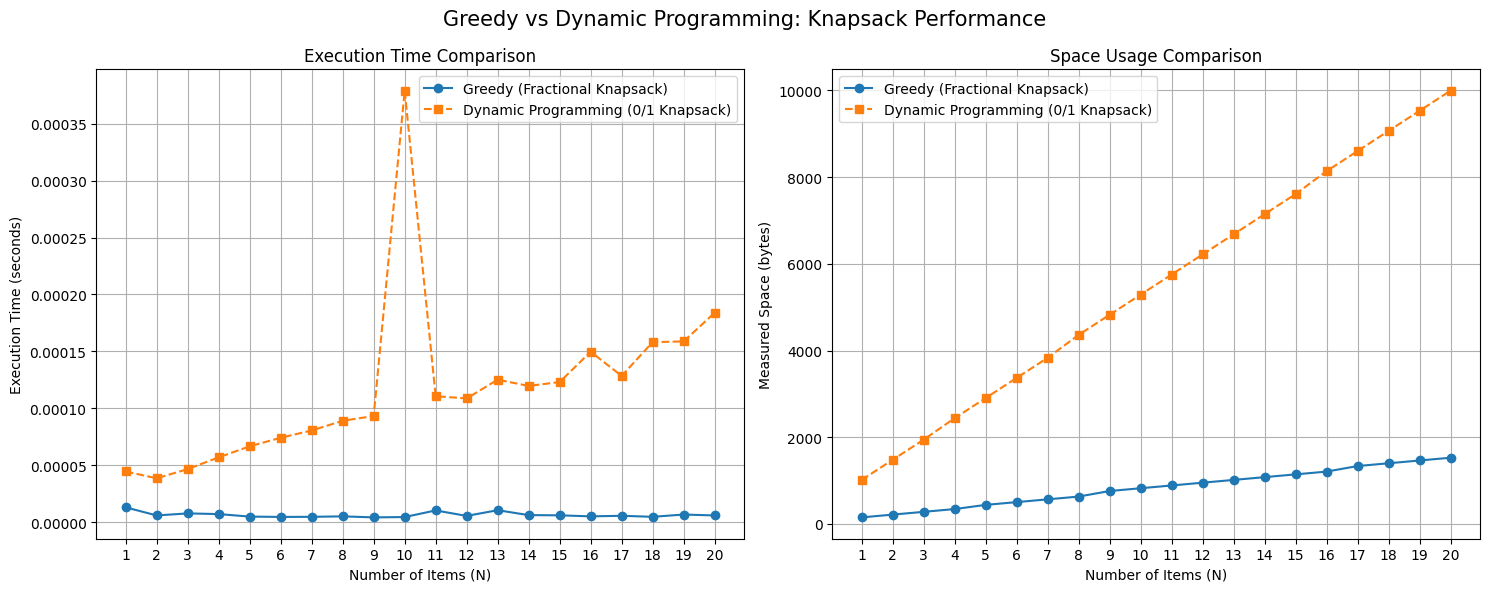

In [8]:

import time
import sys
import matplotlib.pyplot as plt


# ============================================================
# 1. GREEDY ALGORITHM - FRACTIONAL KNAPSACK
# ============================================================

def fractional_knapsack(items, capacity):
    sorted_items = sorted(
        items,
        key=lambda item: item[1] / item[2],
        reverse=True
    )

    selected = []
    total_value = 0

    for item_id, value, weight in sorted_items:
        if capacity <= 0:
            break

        if weight <= capacity:
            selected.append(item_id)
            total_value += value
            capacity -= weight
        else:
            total_value += value * (capacity / weight)
            selected.append(item_id)
            capacity = 0

    return selected, total_value


# ============================================================
# 2. DYNAMIC PROGRAMMING - 0/1 KNAPSACK
# ============================================================

def knapsack_01(items, capacity):
    n = len(items)

    dp = [
        [0] * (capacity + 1)
        for _ in range(n + 1)
    ]

    for i in range(1, n + 1):
        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):
            if weight > w:
                dp[i][w] = dp[i - 1][w]
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            item_id, value, weight = items[i - 1]
            selected.append(item_id)
            w -= weight

    selected.reverse()

    return selected, dp[n][capacity], dp


# ============================================================
# 3. TEST BOTH ALGORITHMS FOR N = 1 TO 20
# ============================================================

n_values = list(range(1, 21))
capacity = 50

fractional_times = []
fractional_spaces = []

zero_one_times = []
zero_one_spaces = []

print("=" * 55)
print("GREEDY VS DYNAMIC PROGRAMMING")
print("=" * 55)

for n in n_values:

    # Generate items
    items = [
        (i, i * 40, i * 5)
        for i in range(1, n + 1)
    ]

    # --------------------------------------------------------
    # Greedy / Fractional Knapsack
    # --------------------------------------------------------

    start = time.perf_counter()

    selected_greedy, value_greedy = fractional_knapsack(
        items, capacity
    )

    greedy_time = time.perf_counter() - start

    greedy_space = sys.getsizeof(items) + sum(
        sys.getsizeof(item) for item in items
    )

    fractional_times.append(greedy_time)
    fractional_spaces.append(greedy_space)

    # --------------------------------------------------------
    # Dynamic Programming / 0/1 Knapsack
    # --------------------------------------------------------

    start = time.perf_counter()

    selected_dp, value_dp, dp = knapsack_01(
        items, capacity
    )

    dp_time = time.perf_counter() - start

    dp_space = sys.getsizeof(dp) + sum(
        sys.getsizeof(row) for row in dp
    )

    zero_one_times.append(dp_time)
    zero_one_spaces.append(dp_space)

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print(f"\nNumber of items (N): {n}")
    print("-" * 40)

    print("Greedy (Fractional Knapsack):")
    print("Selected items:", selected_greedy)
    print("Maximum value:", value_greedy)
    print(f"Execution time: {greedy_time:.8f} seconds")
    print("Measured space:", greedy_space, "bytes")

    print("\nDynamic Programming (0/1 Knapsack):")
    print("Selected items:", selected_dp)
    print("Maximum value:", value_dp)
    print(f"Execution time: {dp_time:.8f} seconds")
    print("DP table space:", dp_space, "bytes")


# ============================================================
# 4. COMBINED GRAPHS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ------------------------------------------------------------
# Graph 1: Execution Time Comparison
# ------------------------------------------------------------

axes[0].plot(
    n_values,
    fractional_times,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[0].plot(
    n_values,
    zero_one_times,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[0].set_xlabel("Number of Items (N)")
axes[0].set_ylabel("Execution Time (seconds)")
axes[0].set_title("Execution Time Comparison")
axes[0].set_xticks(n_values)
axes[0].legend()
axes[0].grid(True)


# ------------------------------------------------------------
# Graph 2: Space Usage Comparison
# ------------------------------------------------------------

axes[1].plot(
    n_values,
    fractional_spaces,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[1].plot(
    n_values,
    zero_one_spaces,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[1].set_xlabel("Number of Items (N)")
axes[1].set_ylabel("Measured Space (bytes)")
axes[1].set_title("Space Usage Comparison")
axes[1].set_xticks(n_values)
axes[1].legend()
axes[1].grid(True)


# ------------------------------------------------------------
# Display both graphs
# ------------------------------------------------------------

fig.suptitle(
    "Greedy vs Dynamic Programming: Knapsack Performance",
    fontsize=15
)

plt.tight_layout()
plt.show()


GREEDY VS DYNAMIC PROGRAMMING

Number of items (N): 1
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1]
Maximum value: 40
Execution time: 0.00001270 seconds
Measured space: 152 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1]
Maximum value: 40
Execution time: 0.00004720 seconds
DP table space: 1016 bytes

Number of items (N): 2
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1, 2]
Maximum value: 120
Execution time: 0.00000690 seconds
Measured space: 216 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1, 2]
Maximum value: 120
Execution time: 0.00004070 seconds
DP table space: 1480 bytes

Number of items (N): 3
----------------------------------------
Greedy (Fractional Knapsack):
Selected items: [1, 2, 3]
Maximum value: 240
Execution time: 0.00000950 seconds
Measured space: 280 bytes

Dynamic Programming (0/1 Knapsack):
Selected items: [1, 2, 3]
Maximum value: 240
Execution time: 0

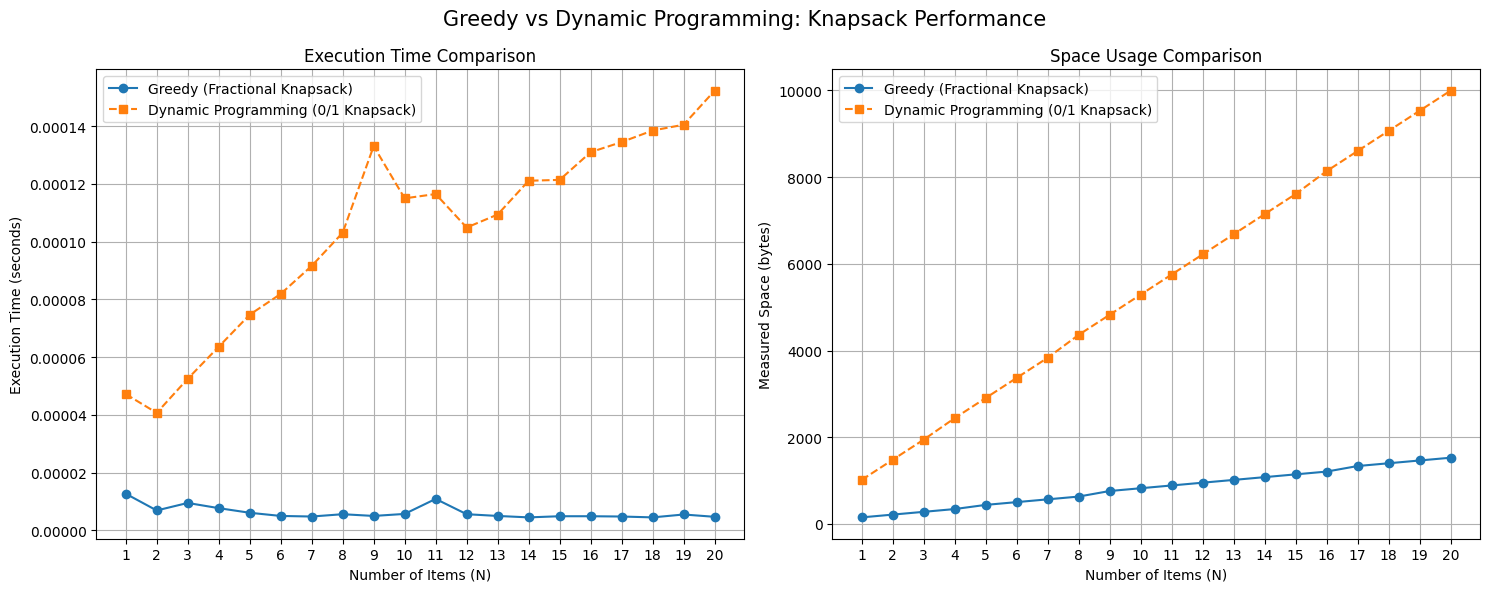

In [9]:

import time
import sys
import matplotlib.pyplot as plt


# ============================================================
# 1. GREEDY ALGORITHM - FRACTIONAL KNAPSACK
# ============================================================

def fractional_knapsack(items, capacity):
    sorted_items = sorted(
        items,
        key=lambda item: item[1] / item[2],
        reverse=True
    )

    selected = []
    total_value = 0

    for item_id, value, weight in sorted_items:
        if capacity <= 0:
            break

        if weight <= capacity:
            selected.append(item_id)
            total_value += value
            capacity -= weight
        else:
            total_value += value * (capacity / weight)
            selected.append(item_id)
            capacity = 0

    return selected, total_value


# ============================================================
# 2. DYNAMIC PROGRAMMING - 0/1 KNAPSACK
# ============================================================

def knapsack_01(items, capacity):
    n = len(items)

    dp = [
        [0] * (capacity + 1)
        for _ in range(n + 1)
    ]

    for i in range(1, n + 1):
        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):
            if weight > w:
                dp[i][w] = dp[i - 1][w]
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            item_id, value, weight = items[i - 1]
            selected.append(item_id)
            w -= weight

    selected.reverse()

    return selected, dp[n][capacity], dp


# ============================================================
# 3. TEST BOTH ALGORITHMS FOR N = 1 TO 20
# ============================================================

n_values = list(range(1, 21))
capacity = 50

fractional_times = []
fractional_spaces = []

zero_one_times = []
zero_one_spaces = []

print("=" * 55)
print("GREEDY VS DYNAMIC PROGRAMMING")
print("=" * 55)

for n in n_values:

    # Generate items
    items = [
        (i, i * 40, i * 5)
        for i in range(1, n + 1)
    ]

    # --------------------------------------------------------
    # Greedy / Fractional Knapsack
    # --------------------------------------------------------

    start = time.perf_counter()

    selected_greedy, value_greedy = fractional_knapsack(
        items, capacity
    )

    greedy_time = time.perf_counter() - start

    greedy_space = sys.getsizeof(items) + sum(
        sys.getsizeof(item) for item in items
    )

    fractional_times.append(greedy_time)
    fractional_spaces.append(greedy_space)

    # --------------------------------------------------------
    # Dynamic Programming / 0/1 Knapsack
    # --------------------------------------------------------

    start = time.perf_counter()

    selected_dp, value_dp, dp = knapsack_01(
        items, capacity
    )

    dp_time = time.perf_counter() - start

    dp_space = sys.getsizeof(dp) + sum(
        sys.getsizeof(row) for row in dp
    )

    zero_one_times.append(dp_time)
    zero_one_spaces.append(dp_space)

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print(f"\nNumber of items (N): {n}")
    print("-" * 40)

    print("Greedy (Fractional Knapsack):")
    print("Selected items:", selected_greedy)
    print("Maximum value:", value_greedy)
    print(f"Execution time: {greedy_time:.8f} seconds")
    print("Measured space:", greedy_space, "bytes")

    print("\nDynamic Programming (0/1 Knapsack):")
    print("Selected items:", selected_dp)
    print("Maximum value:", value_dp)
    print(f"Execution time: {dp_time:.8f} seconds")
    print("DP table space:", dp_space, "bytes")


# ============================================================
# 4. COMBINED GRAPHS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ------------------------------------------------------------
# Graph 1: Execution Time Comparison
# ------------------------------------------------------------

axes[0].plot(
    n_values,
    fractional_times,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[0].plot(
    n_values,
    zero_one_times,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[0].set_xlabel("Number of Items (N)")
axes[0].set_ylabel("Execution Time (seconds)")
axes[0].set_title("Execution Time Comparison")
axes[0].set_xticks(n_values)
axes[0].legend()
axes[0].grid(True)


# ------------------------------------------------------------
# Graph 2: Space Usage Comparison
# ------------------------------------------------------------

axes[1].plot(
    n_values,
    fractional_spaces,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[1].plot(
    n_values,
    zero_one_spaces,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[1].set_xlabel("Number of Items (N)")
axes[1].set_ylabel("Measured Space (bytes)")
axes[1].set_title("Space Usage Comparison")
axes[1].set_xticks(n_values)
axes[1].legend()
axes[1].grid(True)


# ------------------------------------------------------------
# Display both graphs
# ------------------------------------------------------------

fig.suptitle(
    "Greedy vs Dynamic Programming: Knapsack Performance",
    fontsize=15
)

plt.tight_layout()
plt.show()


N =  50 | Greedy = 0.00000714 sec | Dynamic Programming = 0.00035273 sec
N = 100 | Greedy = 0.00001312 sec | Dynamic Programming = 0.00059314 sec
N = 150 | Greedy = 0.00001882 sec | Dynamic Programming = 0.00084242 sec
N = 200 | Greedy = 0.00002617 sec | Dynamic Programming = 0.00108402 sec
N = 250 | Greedy = 0.00003224 sec | Dynamic Programming = 0.00134450 sec
N = 300 | Greedy = 0.00003834 sec | Dynamic Programming = 0.00164379 sec
N = 350 | Greedy = 0.00004489 sec | Dynamic Programming = 0.00193817 sec
N = 400 | Greedy = 0.00005169 sec | Dynamic Programming = 0.00223077 sec
N = 450 | Greedy = 0.00005844 sec | Dynamic Programming = 0.00251999 sec
N = 500 | Greedy = 0.00006283 sec | Dynamic Programming = 0.00275742 sec


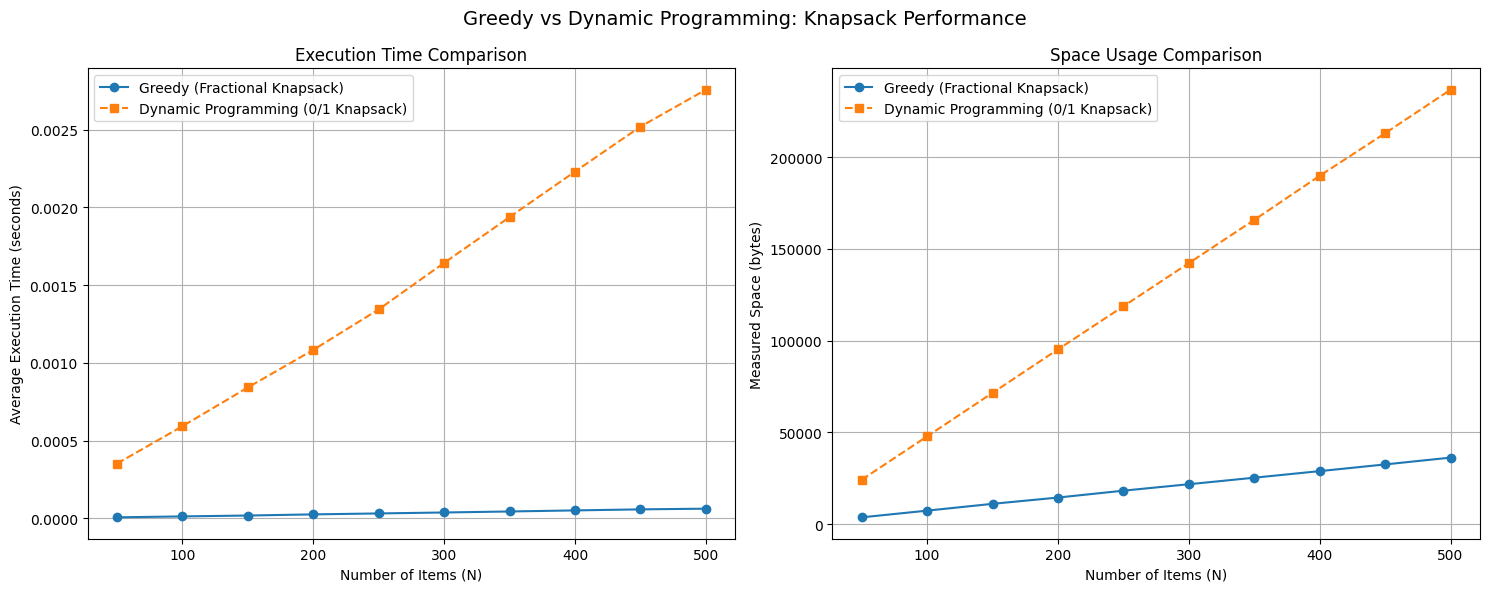

In [10]:

import time
import sys
import matplotlib.pyplot as plt


# ============================================================
# 1. GREEDY - FRACTIONAL KNAPSACK
# ============================================================

def fractional_knapsack(items, capacity):
    sorted_items = sorted(
        items,
        key=lambda item: item[1] / item[2],
        reverse=True
    )

    selected = []
    total_value = 0

    for item_id, value, weight in sorted_items:
        if capacity <= 0:
            break

        if weight <= capacity:
            selected.append(item_id)
            total_value += value
            capacity -= weight
        else:
            total_value += value * (capacity / weight)
            selected.append(item_id)
            capacity = 0

    return selected, total_value


# ============================================================
# 2. DYNAMIC PROGRAMMING - 0/1 KNAPSACK
# ============================================================

def knapsack_01(items, capacity):
    n = len(items)

    dp = [
        [0] * (capacity + 1)
        for _ in range(n + 1)
    ]

    for i in range(1, n + 1):
        item_id, value, weight = items[i - 1]

        for w in range(capacity + 1):
            if weight > w:
                dp[i][w] = dp[i - 1][w]
            else:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            item_id, value, weight = items[i - 1]
            selected.append(item_id)
            w -= weight

    selected.reverse()

    return selected, dp[n][capacity], dp


# ============================================================
# 3. EXPERIMENT SETTINGS
# ============================================================

n_values = list(range(50, 501, 50))
capacity = 50
repeats = 500

fractional_times = []
fractional_spaces = []

zero_one_times = []
zero_one_spaces = []


# ============================================================
# 4. RUN BOTH ALGORITHMS
# ============================================================

for n in n_values:

    items = [
        (i, i * 40, i * 5)
        for i in range(1, n + 1)
    ]

    # ----------------------------------------
    # Greedy: Fractional Knapsack
    # ----------------------------------------

    start = time.perf_counter()

    for _ in range(repeats):
        fractional_knapsack(items, capacity)

    greedy_time = (
        time.perf_counter() - start
    ) / repeats

    greedy_space = sys.getsizeof(items) + sum(
        sys.getsizeof(item) for item in items
    )

    fractional_times.append(greedy_time)
    fractional_spaces.append(greedy_space)

    # ----------------------------------------
    # Dynamic Programming: 0/1 Knapsack
    # ----------------------------------------

    start = time.perf_counter()

    for _ in range(repeats):
        _, _, dp = knapsack_01(items, capacity)

    dp_time = (
        time.perf_counter() - start
    ) / repeats

    dp_space = sys.getsizeof(dp) + sum(
        sys.getsizeof(row) for row in dp
    )

    zero_one_times.append(dp_time)
    zero_one_spaces.append(dp_space)

    print(
        f"N = {n:3d} | "
        f"Greedy = {greedy_time:.8f} sec | "
        f"Dynamic Programming = {dp_time:.8f} sec"
    )


# ============================================================
# 5. PLOT BOTH ALGORITHMS IN THE SAME FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Graph 1: Execution Time
axes[0].plot(
    n_values,
    fractional_times,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[0].plot(
    n_values,
    zero_one_times,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[0].set_xlabel("Number of Items (N)")
axes[0].set_ylabel("Average Execution Time (seconds)")
axes[0].set_title("Execution Time Comparison")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Space Usage
axes[1].plot(
    n_values,
    fractional_spaces,
    marker='o',
    linestyle='-',
    label='Greedy (Fractional Knapsack)'
)

axes[1].plot(
    n_values,
    zero_one_spaces,
    marker='s',
    linestyle='--',
    label='Dynamic Programming (0/1 Knapsack)'
)

axes[1].set_xlabel("Number of Items (N)")
axes[1].set_ylabel("Measured Space (bytes)")
axes[1].set_title("Space Usage Comparison")
axes[1].legend()
axes[1].grid(True)

fig.suptitle(
    "Greedy vs Dynamic Programming: Knapsack Performance",
    fontsize=14
)

plt.tight_layout()
plt.show()
